In [ ]:
from tensorflow.keras import optimizers
from tensorflow.keras import activations
from tensorflow.keras import losses
from tensorflow.keras import layers
from tensorflow.keras import models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
dataset_path = "/content/drive/MyDrive/Deep Learning/animals"

idg = ImageDataGenerator(
    rescale = 1/255,
    rotation_range = 15,
    zoom_range = 0.15,
    horizontal_flip = True,
    validation_split=0.2,
)

dataset_train = idg.flow_from_directory(
    dataset_path,
    shuffle=True,
    subset='training',
    target_size=(256, 256)
)

dataset_validation = idg.flow_from_directory(
    dataset_path,
    shuffle=False,
    subset='validation',
    target_size=(256, 256)
)

Found 1052 images belonging to 5 classes.
Found 262 images belonging to 5 classes.


In [ ]:
model = models.Sequential([
    layers.Input(shape=(256, 256, 3)),
    layers.Conv2D(64,(3,3),activation=activations.relu,padding='same'),
    layers.Conv2D(64,(3,3),activation=activations.relu,padding='same'),
    layers.MaxPooling2D((2,2),strides=2),
    layers.Conv2D(128,(3,3),activation=activations.relu,padding='same'),
    layers.Conv2D(128,(3,3),activation=activations.relu,padding='same'),
    layers.MaxPooling2D((2,2),strides=2),
    layers.Flatten(),
    layers.Dense(512,activation=activations.relu),
    layers.Dropout(0.5),
    layers.Dense(5,activation=activations.softmax)
])

In [ ]:
model.compile(
    optimizer = optimizers.Adam(learning_rate=0.001),
    loss = losses.CategoricalCrossentropy(),
    metrics = ['accuracy']
)

In [ ]:
history = model.fit(
    dataset_train,
    validation_data = dataset_validation,
    epochs=20
)

In [39]:
model.save('/content/drive/MyDrive/Deep Learning/animals.h5')

9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 791ms/step


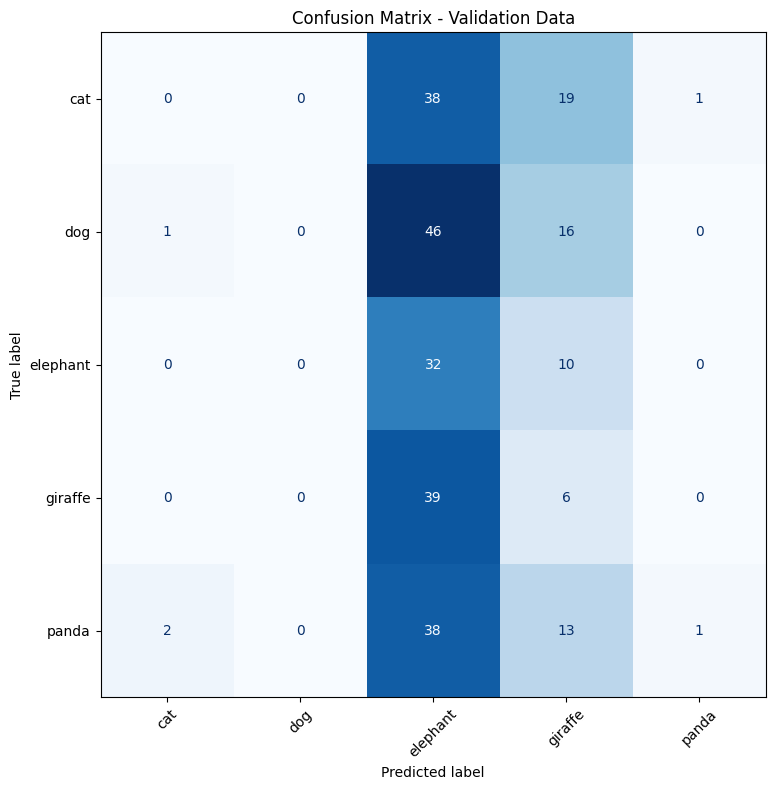

In [42]:
dataset_validation.reset()
predictions = model.predict(dataset_validation)

y_pred = np.argmax(predictions, axis=1)
y_true = dataset_validation.classes

class_names = [
    name for name, index in sorted(
        dataset_validation.class_indices.items(),
        key=lambda item: item[1]
    )
]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
fig, ax = plt.subplots(figsize=(8, 8))
display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)
plt.title("Confusion Matrix - Validation Data")
plt.tight_layout()
plt.show()

In [ ]:
last_val_accuracy = history.history["val_accuracy"][-1]
last_val_loss = history.history["val_loss"][-1]

print(f"Validation Accuracy: {last_val_accuracy * 100:.2f}%")
print(f"Validation Loss: {last_val_loss:.4f}")

Validation Accuracy: 49.24%
Validation Loss: 1.2548


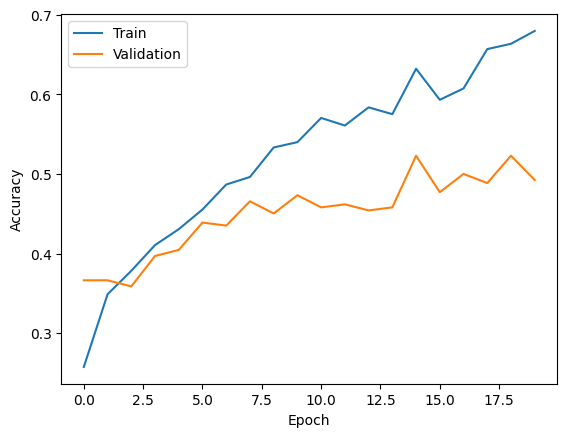

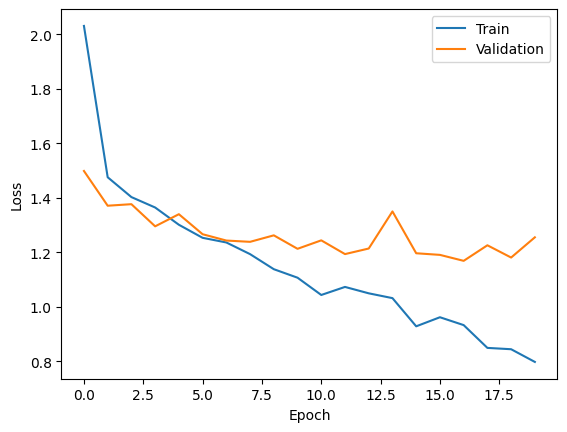

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
image = cv2.imread("/content/dog-1.jpg")
image = cv2.resize(image,(256,256))
image = image / 255.0
image = np.expand_dims(image, axis=0)
output = model.predict(image)
predicted = output.argmax()
if dataset_train.class_indices['cat'] == predicted:
    print("🐈")
elif dataset_train.class_indices['dog'] == predicted:
    print("🐶")
elif dataset_train.class_indices['elephant'] == predicted:
    print("🐘")
elif dataset_train.class_indices['giraffe'] == predicted:
    print("🦒")
elif dataset_train.class_indices['panda'] == predicted:
    print("🐼")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
🐶


In [ ]:
image = cv2.imread("/content/panda-1.jpg")
image = cv2.resize(image,(256,256))
image = image / 255.0
image = np.expand_dims(image, axis=0)
output = model.predict(image)
predicted = output.argmax()
if dataset_train.class_indices['cat'] == predicted:
    print("🐈")
elif dataset_train.class_indices['dog'] == predicted:
    print("🐶")
elif dataset_train.class_indices['elephant'] == predicted:
    print("🐘")
elif dataset_train.class_indices['giraffe'] == predicted:
    print("🦒")
elif dataset_train.class_indices['panda'] == predicted:
    print("🐼")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
🐼
